<a href="https://colab.research.google.com/github/AndresAvella09/Proyecto_Multimodal/blob/main/notebooks/05_anios_y_peliculas_recientes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/AndresAvella09/Proyecto_Multimodal/blob/main/notebooks/05_anios_y_peliculas_recientes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05 · Año de estreno y películas recientes

**Pregunta del proyecto:** ¿el modelo depende más del póster o de la sinopsis, y ese desbalance cambia con películas nuevas?

El notebook 04 entrenó tres modelos (solo póster, solo sinopsis, fusión) con MM-IMDB. Para probarlos con películas
recientes de forma justa, este notebook prepara los datos de la comparativa temporal:


| Sección | Qué hace | Archivo que guarda |
|---|---|---|
| 1-2 | Descarga los datasets públicos de IMDb y les pega el **año** y los **votos** a MM-IMDB | — |
| 3 | ¿Cuántas películas hay por década? ¿Alcanza para el **Nivel 1** (viejas vs. nuevas dentro de MM-IMDB)? | — |
| 4 | Compara las etiquetas de MM-IMDB con las de IMDb hoy (IMDb da **máximo 3 géneros**) y guarda ambas | `mmimdb_con_anio.parquet` |
| 5 | Arma el grupo de **películas 2020-2026** y elige ~3 000 (Nivel 2) | `recientes_candidatas.parquet`, `recientes_seleccion.parquet` |
| 6 | Arma la **muestra control**: películas viejas que se bajarán de TMDB igual que las nuevas | `control_viejas.parquet` |
| 7 | Define los **géneros que entran en la comparación** (los que tienen suficientes películas recientes) | `generos_comparacion.json` |

**Fuente:** [IMDb Non-Commercial Datasets](https://developer.imdb.com/non-commercial-datasets): uso personal y no comercial, se actualizan a diario.
Los pósters y sinopsis de las películas nuevas se descargan de TMDB en el notebook 06.

In [ ]:
import os, sys, json, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt

EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

# Carpeta del proyecto en Drive (se puede cambiar con una variable de entorno)
DATA = os.environ.get('PM_DATA', '/content/drive/MyDrive/proyecto_multimodal/data')
IMDB_DIR = os.path.join(DATA, 'imdb')          # aquí quedan los .tsv.gz de IMDb
os.makedirs(IMDB_DIR, exist_ok=True)

df = pd.read_parquet(os.path.join(DATA, 'mmimdb_meta.parquet'))
GENEROS = list(df.columns[4:])
print(df.shape, '|', len(GENEROS), 'géneros')

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'figure.dpi': 110})
AZUL, NARANJA, GRIS = '#2563eb', '#ea580c', '#9ca3af'

Mounted at /content/drive
(25959, 27) | 23 géneros


## 1. Descargar los datasets de IMDb

Usamos dos archivos:

- `title.basics.tsv.gz`: tipo de título, **año de estreno**, duración y **hasta 3 géneros** (~1 GB descomprimido).
- `title.ratings.tsv.gz`: rating promedio y **número de votos**, que sirve para medir popularidad.

Se guardan en Drive y solo se descargan la primera vez.

In [ ]:
BASE_URL = 'https://datasets.imdbws.com/'

def descargar(nombre):
    ruta = os.path.join(IMDB_DIR, nombre)
    if os.path.exists(ruta):
        print(f'{nombre}: ya estaba ({os.path.getsize(ruta) / 1e6:.0f} MB)')
    else:
        print(f'Descargando {nombre}...')
        urllib.request.urlretrieve(BASE_URL + nombre, ruta)
        print(f'  listo ({os.path.getsize(ruta) / 1e6:.0f} MB)')
    return ruta

ruta_basics = descargar('title.basics.tsv.gz')
ruta_ratings = descargar('title.ratings.tsv.gz')

title.basics.tsv.gz: ya estaba (230 MB)
title.ratings.tsv.gz: ya estaba (9 MB)


In [ ]:
# Solo leemos las columnas necesarias. '\\N' es como IMDb marca los vacíos.
# quoting=3 (QUOTE_NONE): algunos títulos traen comillas sueltas que rompen el parser.
basics = pd.read_csv(ruta_basics, sep='\t', na_values='\\N', quoting=3,
                     usecols=['tconst', 'titleType', 'primaryTitle', 'isAdult',
                              'startYear', 'runtimeMinutes', 'genres'],
                     dtype={'tconst': str, 'titleType': 'category', 'primaryTitle': str,
                            'isAdult': 'Int8', 'startYear': 'Int16',
                            'runtimeMinutes': str, 'genres': str})
ratings = pd.read_csv(ruta_ratings, sep='\t', na_values='\\N',
                      dtype={'tconst': str, 'averageRating': float, 'numVotes': 'Int32'})

imdb = basics.merge(ratings, on='tconst', how='left')
del basics, ratings
print(f'Títulos en IMDb: {len(imdb):,}')
print(imdb['titleType'].value_counts().head(8).to_string())

Títulos en IMDb: 12,918,857
titleType
tvEpisode       9997191
short           1166803
movie            759695
video            332984
tvSeries         307569
tvMovie          156835
tvMiniSeries      73972
tvSpecial         61875


## 2. Pegar año y votos a MM-IMDB

Los ids de MM-IMDB son 7 dígitos (`0028219`); en IMDb el mismo título es `tt0028219`.

In [ ]:
df['tconst'] = 'tt' + df['imdb_id'].astype(str).str.zfill(7)

cols = ['tconst', 'titleType', 'primaryTitle', 'startYear', 'genres', 'averageRating', 'numVotes']
mm = df.merge(imdb[cols], on='tconst', how='left')
mm = mm.rename(columns={'startYear': 'anio', 'genres': 'generos_imdb_hoy',
                        'primaryTitle': 'titulo', 'titleType': 'tipo_imdb'})

encontradas = mm['anio'].notna()
print(f'Películas de MM-IMDB con año en IMDb: {encontradas.sum():,} de {len(mm):,} ({encontradas.mean():.1%})')
print('Tipo de título en IMDb:')
print(mm['tipo_imdb'].value_counts(dropna=False).to_string())

Películas de MM-IMDB con año en IMDb: 25,915 de 25,959 (99.8%)
Tipo de título en IMDb:
tipo_imdb
movie           23547
tvMovie           936
video             610
short             404
tvMiniSeries      218
tvSpecial         103
tvEpisode          64
NaN                44
tvSeries           17
tvShort            16
videoGame           0
tvPilot             0


## 3. ¿Cuántas películas hay por década?

Esto decide si el **Nivel 1** (entrenar con películas viejas y evaluar con más nuevas, todo dentro de MM-IMDB) tiene suficientes datos en cada grupo.

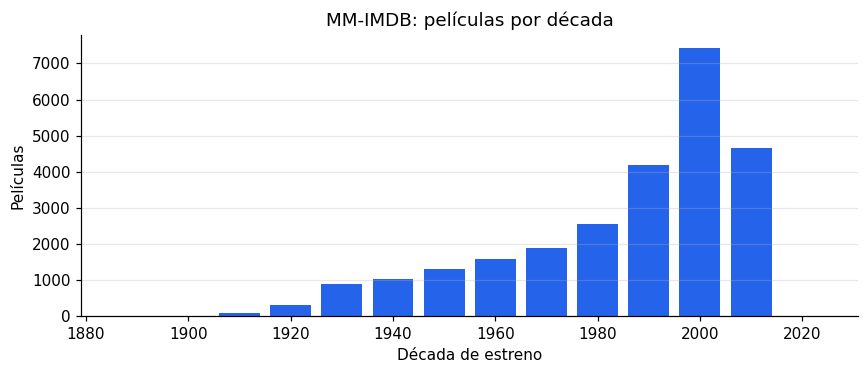

decada
1890      12
1900       7
1910      91
1920     298
1930     881
1940    1032
1950    1311
1960    1578
1970    1897
1980    2554
1990    4177
2000    7425
2010    4651
2020       1

Rango: 1891 a 2021 | mediana: 1998

Año mediano por partición (si son parecidos, el split oficial es aleatorio en el tiempo):
particion
dev      1998.0
test     1997.0
train    1998.0


In [ ]:
mm['decada'] = (mm['anio'] // 10 * 10).astype('Int16')
por_decada = mm.groupby('decada', dropna=True).size()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(por_decada.index.astype(int), por_decada.values, width=8, color=AZUL)
ax.set_xlabel('Década de estreno'); ax.set_ylabel('Películas')
ax.set_title('MM-IMDB: películas por década')
ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

print(por_decada.to_string())
print(f"\nRango: {int(mm['anio'].min())} a {int(mm['anio'].max())} | mediana: {int(mm['anio'].median())}")
print('\nAño mediano por partición (si son parecidos, el split oficial es aleatorio en el tiempo):')
print(mm.groupby('particion')['anio'].median().to_string())

In [ ]:
# Cortes candidatos para el Nivel 1: cuántas películas quedan antes y después
print(f"{'corte':>6} | {'antes':>7} | {'desde':>7} | % desde")
for corte in [1990, 1995, 2000, 2005, 2010]:
    antes = int((mm['anio'] < corte).sum()); desde = int((mm['anio'] >= corte).sum())
    print(f'{corte:>6} | {antes:>7,} | {desde:>7,} | {desde / (antes + desde):.0%}')

 corte |   antes |   desde | % desde
  1990 |   9,661 |  16,254 | 63%
  1995 |  11,360 |  14,555 | 56%
  2000 |  13,838 |  12,077 | 47%
  2005 |  16,936 |   8,979 | 35%
  2010 |  21,263 |   4,652 | 18%


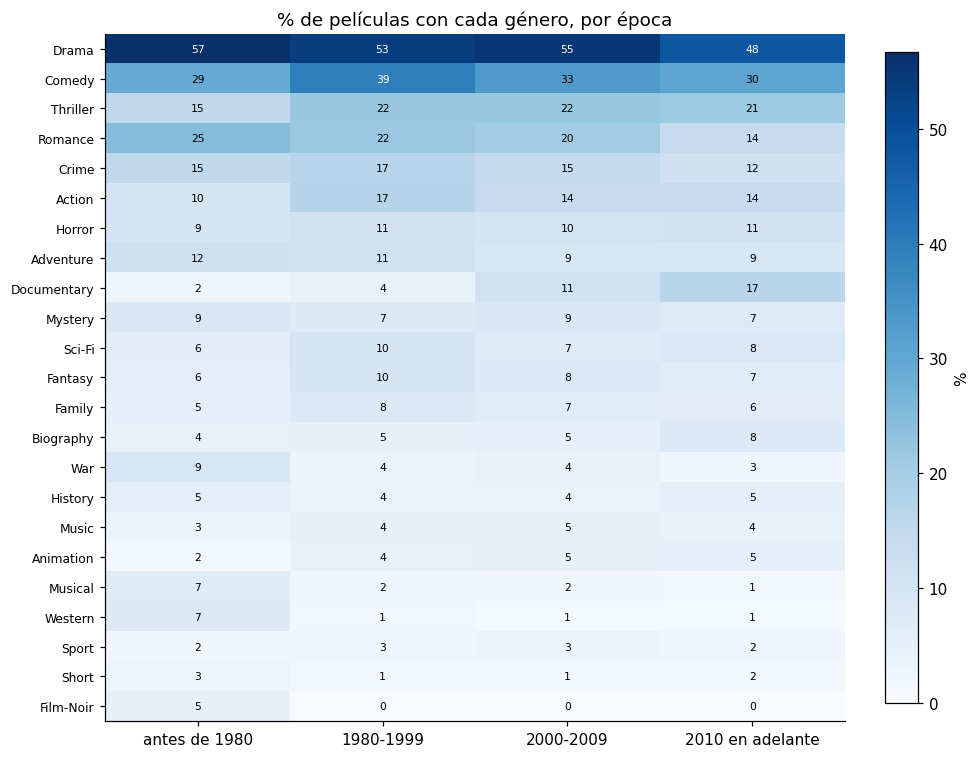

Películas por época:
anio
antes de 1980       7107
1980-1999           6731
2000-2009           7425
2010 en adelante    4652


In [ ]:
# ¿Cambia la mezcla de géneros con el tiempo? (si cambia mucho, ya hay 'deriva' antes de mirar los modelos)
epoca = pd.cut(mm['anio'], bins=[0, 1979, 1999, 2009, 2100],
               labels=['antes de 1980', '1980-1999', '2000-2009', '2010 en adelante'])
prev_epoca = mm.groupby(epoca, observed=True)[GENEROS].mean().T * 100
prev_epoca = prev_epoca.loc[prev_epoca.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(prev_epoca.values, cmap='Blues', aspect='auto')
ax.set_xticks(range(prev_epoca.shape[1]), prev_epoca.columns)
ax.set_yticks(range(len(prev_epoca)), prev_epoca.index, fontsize=8)
for i in range(prev_epoca.shape[0]):
    for j in range(prev_epoca.shape[1]):
        v = prev_epoca.values[i, j]
        ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=7,
                color='white' if v > prev_epoca.values.max() * 0.6 else 'black')
ax.set_title('% de películas con cada género, por época')
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.04, label='%')
plt.tight_layout(); plt.show()

print('Películas por época:')
print(epoca.value_counts().sort_index().to_string())

## 4. ¿Las etiquetas de MM-IMDB coinciden con las de IMDb hoy?

Esto importa para la comparación: las películas nuevas solo pueden tener etiquetas del archivo de IMDb, que trae **máximo 3 géneros**.
Si a las viejas les evaluamos con las etiquetas de MM-IMDB (hasta 10 géneros), la comparación no es justa:
una película nueva "pierde" géneros por cómo se etiquetó, no porque el modelo falle.

**Decisión que sale de aquí:** para la comparativa temporal, evaluar viejas y nuevas con **la misma fuente de etiquetas** (IMDb hoy).
Por eso este notebook guarda las dos versiones de etiquetas para MM-IMDB: las originales (`Drama`, `Comedy`, ...) y las de hoy (`hoy_Drama`, `hoy_Comedy`, ...).

In [ ]:
def a_multietiqueta(serie_generos, generos=GENEROS):
    # 'Drama,Crime' -> matriz 0/1 en el orden de GENEROS (ignora géneros fuera de la lista)
    listas = serie_generos.fillna('').str.split(',')
    return np.array([[int(g in set(l)) for g in generos] for l in listas], dtype=np.int8)

# Etiquetas de hoy para TODAS las filas (en orden de fila_hdf5); sin dato en IMDb -> fila en cero
Y_hoy_todas = a_multietiqueta(mm['generos_imdb_hoy'])
mm['etiquetas_hoy_ok'] = mm['generos_imdb_hoy'].notna() & (Y_hoy_todas.sum(axis=1) > 0)
mm['es_pelicula'] = mm['tipo_imdb'] == 'movie'

ok = mm['etiquetas_hoy_ok'].values
Y_mm = mm.loc[ok, GENEROS].values
Y_hoy = Y_hoy_todas[ok]
print(f'Películas con etiquetas de hoy: {ok.sum():,} | de esas, de cine (movie): {mm.loc[ok, "es_pelicula"].sum():,}')

n_mm, n_hoy = Y_mm.sum(axis=1), Y_hoy.sum(axis=1)
print(f'Géneros por película  | MM-IMDB: media {n_mm.mean():.2f}, máx {n_mm.max()}'
      f'  | IMDb hoy: media {n_hoy.mean():.2f}, máx {n_hoy.max()}')
print(f'Películas con más de 3 géneros en MM-IMDB: {(n_mm > 3).mean():.1%}')
print(f'Etiquetas idénticas en ambas fuentes:   {(Y_mm == Y_hoy).all(axis=1).mean():.1%}')
print(f'IMDb hoy ⊆ MM-IMDB (solo se recortaron): {((Y_hoy <= Y_mm).all(axis=1)).mean():.1%}')

Películas con etiquetas de hoy: 25,914 | de esas, de cine (movie): 23,546
Géneros por película  | MM-IMDB: media 2.48, máx 10  | IMDb hoy: media 2.35, máx 3
Películas con más de 3 géneros en MM-IMDB: 18.8%
Etiquetas idénticas en ambas fuentes:   59.7%
IMDb hoy ⊆ MM-IMDB (solo se recortaron): 78.5%


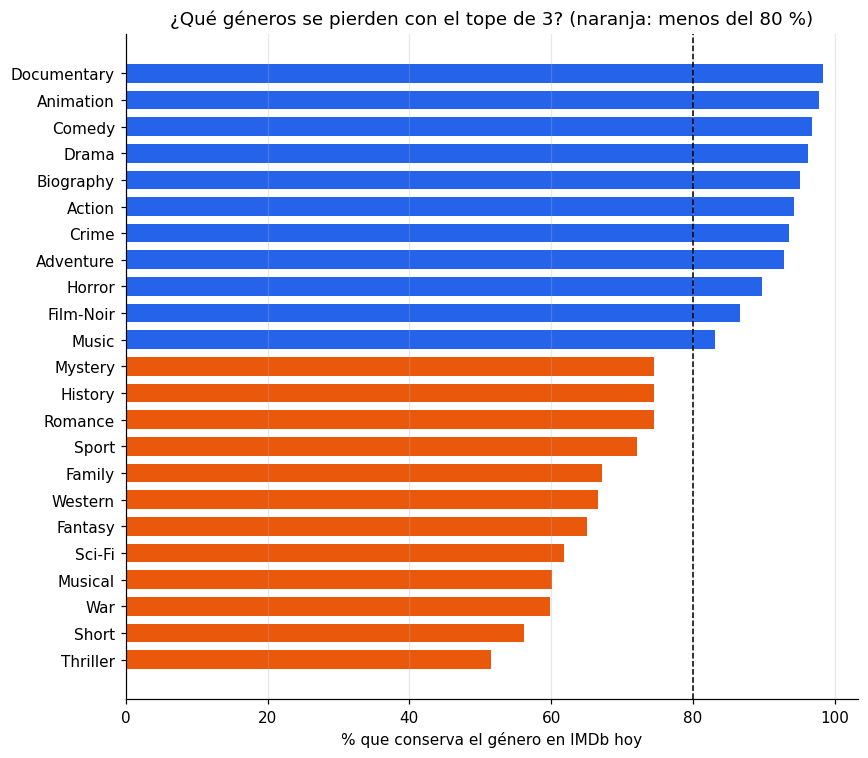

Thriller       51.5
Short          56.2
War            59.9
Musical        60.1
Sci-Fi         61.9
Fantasy        65.0
Western        66.7
Family         67.1
Sport          72.2
Romance        74.4
History        74.5
Mystery        74.6
Music          83.2
Film-Noir      86.7
Horror         89.7
Adventure      92.8
Crime          93.6
Action         94.2
Biography      95.1
Drama          96.2
Comedy         96.8
Animation      97.8
Documentary    98.4


In [ ]:
# Por género: de las películas que MM-IMDB marca con g, ¿qué % sigue teniendo g en IMDb hoy?
se_mantiene = pd.Series(
    [(Y_hoy[:, j] & Y_mm[:, j]).sum() / max(Y_mm[:, j].sum(), 1) for j in range(len(GENEROS))],
    index=GENEROS).sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
colores = [NARANJA if v < 0.8 else AZUL for v in se_mantiene.values]
ax.barh(se_mantiene.index, se_mantiene.values * 100, color=colores, height=0.7)
ax.axvline(80, color='black', lw=1, ls='--')
ax.set_xlabel('% que conserva el género en IMDb hoy')
ax.set_title('¿Qué géneros se pierden con el tope de 3? (naranja: menos del 80 %)')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

print((se_mantiene * 100).round(1).to_string())

In [ ]:
# ¿Cuánto es recorte (tope de 3) y cuánto es reetiquetado?
# En las películas con 3 géneros o menos el tope no las afecta: si cambian, IMDb las reetiquetó.
pocas = n_mm <= 3
cambio_pocas = 1 - (Y_mm[pocas] == Y_hoy[pocas]).all(axis=1).mean()
print(f'Películas con ≤3 géneros en MM-IMDB: {pocas.mean():.1%}')
print(f'  de esas, con etiquetas distintas hoy: {cambio_pocas:.1%}  <- reetiquetado puro (no es por el tope)')
print(f'Películas con >3 géneros: {(~pocas).mean():.1%} (estas cambian sí o sí por el tope)')

Películas con ≤3 géneros en MM-IMDB: 81.2%
  de esas, con etiquetas distintas hoy: 26.4%  <- reetiquetado puro (no es por el tope)
Películas con >3 géneros: 18.8% (estas cambian sí o sí por el tope)


In [ ]:
# Guardar MM-IMDB con año + etiquetas de hoy (columnas hoy_<género>), en orden de fila_hdf5
hoy = pd.DataFrame(Y_hoy_todas, columns=[f'hoy_{g}' for g in GENEROS], index=mm.index)
guardar = pd.concat([mm.drop(columns=['decada']), hoy], axis=1)
assert (guardar['fila_hdf5'].values == np.arange(len(guardar))).all(), 'debe quedar en orden del HDF5'
guardar.to_parquet(os.path.join(DATA, 'mmimdb_con_anio.parquet'), index=False)
print('Guardado mmimdb_con_anio.parquet:', guardar.shape)

Guardado mmimdb_con_anio.parquet: (25959, 59)


## 5. Grupo de películas recientes (2020-2026)

Criterios, todos ajustables:

- `titleType == 'movie'`, no adultas, con año entre 2020 y 2026 (2026 está incompleto).
- Al menos un género de la lista de 23.
- **Popularidad parecida a MM-IMDB:** MM-IMDB tiene sesgo hacia películas conocidas. Exigimos como mínimo los votos del percentil 10 de MM-IMDB, para no comparar contra películas casi desconocidas con etiquetas ruidosas.
- **Selección final:** no hacen falta las ~12 000 candidatas. Se toman las **más votadas de cada año** (mismo número por año) hasta llegar a ~3 000: menos llamadas a TMDB y etiquetas más confiables.

> Nota: `Short` casi no va a aparecer, porque en IMDb los cortos tienen `titleType == 'short'`, no `'movie'`.

In [ ]:
ANIO_MIN, ANIO_MAX = 2020, 2026
PERCENTIL_VOTOS = 10

votos_min = int(np.nanpercentile(mm['numVotes'].astype(float), PERCENTIL_VOTOS))
print(f'Votos de MM-IMDB hoy: mediana {int(mm["numVotes"].median()):,} | '
      f'percentil {PERCENTIL_VOTOS}: {votos_min:,}  <- umbral mínimo')

nuevas = imdb[(imdb['titleType'] == 'movie') & (imdb['isAdult'] == 0)
              & imdb['startYear'].between(ANIO_MIN, ANIO_MAX)
              & (imdb['numVotes'] >= votos_min)].copy()
nuevas = nuevas[~nuevas['tconst'].isin(mm['tconst'])]   # por si acaso, sin repetidas

Y_nuevas = a_multietiqueta(nuevas['genres'])
nuevas = nuevas[Y_nuevas.sum(axis=1) > 0]
Y_nuevas = Y_nuevas[Y_nuevas.sum(axis=1) > 0]
nuevas[GENEROS] = Y_nuevas

print(f'\nPelículas {ANIO_MIN}-{ANIO_MAX} candidatas: {len(nuevas):,}')
print(nuevas.groupby('startYear').size().to_string())

Votos de MM-IMDB hoy: mediana 4,487 | percentil 10: 674  <- umbral mínimo

Películas 2020-2026 candidatas: 12,248
startYear
2020    1613
2021    1833
2022    2198
2023    2146
2024    1991
2025    1575
2026     892


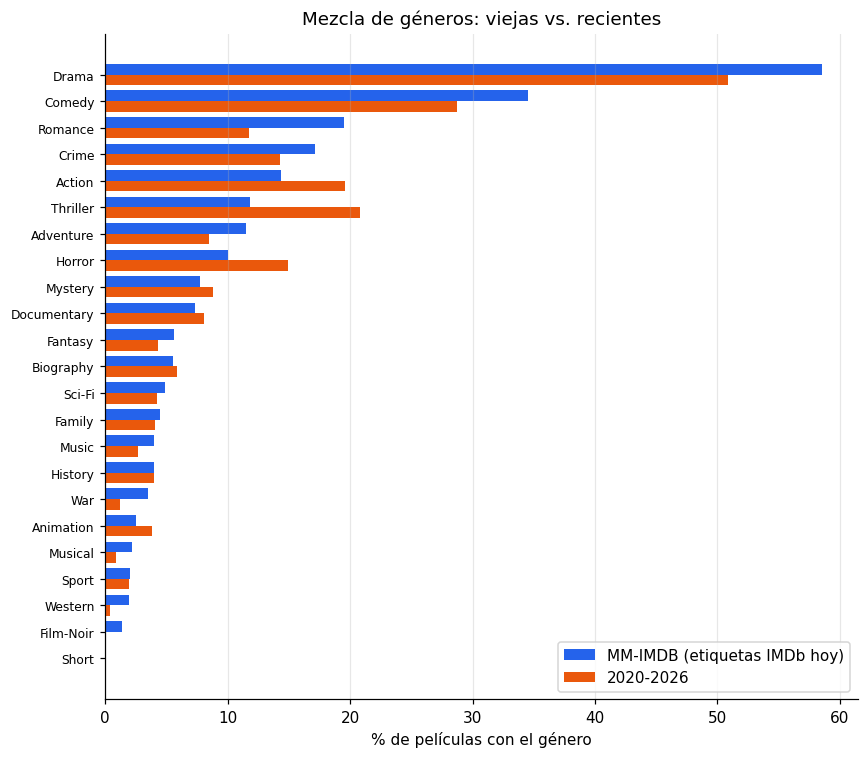

Mayores cambios (puntos porcentuales, recientes − viejas):
Romance     -7.7
Drama       -7.7
Comedy      -5.8
Adventure   -3.0
Animation    1.3
Horror       4.9
Action       5.2
Thriller     9.0


In [ ]:
# Mezcla de géneros: MM-IMDB (etiquetas IMDb hoy, mismo tope de 3) vs. recientes
prev_viejas = pd.Series(Y_hoy[mm.loc[ok, 'es_pelicula'].values].mean(axis=0), index=GENEROS)   # solo cine, como las nuevas
prev_nuevas = nuevas[GENEROS].mean()
orden = prev_viejas.sort_values().index

fig, ax = plt.subplots(figsize=(8, 7))
y = np.arange(len(orden))
ax.barh(y + 0.2, prev_viejas[orden] * 100, height=0.4, color=AZUL, label='MM-IMDB (etiquetas IMDb hoy)')
ax.barh(y - 0.2, prev_nuevas[orden] * 100, height=0.4, color=NARANJA, label=f'{ANIO_MIN}-{ANIO_MAX}')
ax.set_yticks(y, orden, fontsize=8)
ax.set_xlabel('% de películas con el género')
ax.set_title('Mezcla de géneros: viejas vs. recientes')
ax.legend(loc='lower right'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

dif = ((prev_nuevas - prev_viejas) * 100).sort_values()
print('Mayores cambios (puntos porcentuales, recientes − viejas):')
print(pd.concat([dif.head(4), dif.tail(4)]).round(1).to_string())

In [ ]:
cols_out = ['tconst', 'primaryTitle', 'startYear', 'runtimeMinutes', 'genres',
            'averageRating', 'numVotes'] + GENEROS
nuevas[cols_out].rename(columns={'primaryTitle': 'titulo', 'startYear': 'anio',
                                 'genres': 'generos_imdb_hoy'}) \
    .to_parquet(os.path.join(DATA, 'recientes_candidatas.parquet'), index=False)
print('Guardado recientes_candidatas.parquet:', len(nuevas), 'películas')

# Selección: las más votadas de cada año, el mismo número por año
N_RECIENTES = 3000
por_anio = int(np.ceil(N_RECIENTES / nuevas['startYear'].nunique()))
seleccion = (nuevas.sort_values('numVotes', ascending=False)
                   .groupby('startYear').head(por_anio))
print(f'\nSelección: {len(seleccion):,} películas (hasta {por_anio} por año)')
print(f"Votos en la selección: mediana {int(seleccion['numVotes'].median()):,} | mínimo {int(seleccion['numVotes'].min()):,}"
      f"  (MM-IMDB: mediana {int(mm['numVotes'].median()):,})")
print(seleccion.groupby('startYear').size().to_string())

seleccion[cols_out].rename(columns={'primaryTitle': 'titulo', 'startYear': 'anio',
                                    'genres': 'generos_imdb_hoy'}) \
    .to_parquet(os.path.join(DATA, 'recientes_seleccion.parquet'), index=False)
print('Guardado recientes_seleccion.parquet')

Guardado recientes_candidatas.parquet: 12248 películas

Selección: 3,003 películas (hasta 429 por año)
Votos en la selección: mediana 17,976 | mínimo 2,366  (MM-IMDB: mediana 4,487)
startYear
2020    429
2021    429
2022    429
2023    429
2024    429
2025    429
2026    429
Guardado recientes_seleccion.parquet


## 6. Muestra control: películas viejas que pasan por el mismo camino

Las sinopsis de TMDB son distintas a las de MM-IMDB (más cortas, otro estilo) y los pósters tienen otro procesamiento.
Para separar el **efecto de la época** del **efecto de la fuente**, bajaremos de TMDB también un grupo de películas **viejas del test de MM-IMDB**:

| Grupo | Época | Fuente de póster y sinopsis |
|---|---|---|
| test MM-IMDB | vieja | MM-IMDB |
| **control** | vieja | **TMDB** |
| recientes | nueva | TMDB |

- control vs. test MM-IMDB → efecto de la **fuente**
- recientes vs. control → efecto de la **época**

La muestra se toma solo del **test** (nunca del train, porque con el train se entrenaron los modelos del notebook 04),
solo de títulos que IMDb clasifica como **cine** (igual que las recientes) y estratificada por década.

In [ ]:
N_CONTROL, SEMILLA = 1500, 42

test = guardar[(guardar['particion'] == 'test') & guardar['anio'].notna()
              & guardar['es_pelicula'] & guardar['etiquetas_hoy_ok']].copy()
test['decada'] = (test['anio'] // 10 * 10).astype(int)
frac = min(1.0, N_CONTROL / len(test))
control = test.groupby('decada').sample(frac=frac, random_state=SEMILLA)

print(f'Muestra control: {len(control):,} películas del test')
print(control['decada'].value_counts().sort_index().to_string())

control[['fila_hdf5', 'tconst', 'titulo', 'anio', 'generos_imdb_hoy'] + GENEROS
        + [f'hoy_{g}' for g in GENEROS]] \
    .to_parquet(os.path.join(DATA, 'control_viejas.parquet'), index=False)
print('Guardado control_viejas.parquet')

Muestra control: 1,501 películas del test
decada
1910      3
1920     18
1930     60
1940     60
1950     81
1960    100
1970    116
1980    155
1990    233
2000    420
2010    255
Guardado control_viejas.parquet


## 7. ¿Qué géneros entran en la comparación?

Para calcular el F1 de un género en las películas recientes hacen falta suficientes películas de ese género.
Con muy pocas, el F1 salta mucho por azar. Regla: un género entra si tiene **al menos `MIN_POSITIVOS` películas en la
selección reciente**. Los que no llegan (se espera Short y Film-Noir, quizá Western) se reportan aparte, explicando por qué.

In [ ]:
MIN_POSITIVOS = 30

positivos = seleccion[GENEROS].sum().sort_values()
GENEROS_COMP = [g for g in GENEROS if positivos[g] >= MIN_POSITIVOS]
fuera = [g for g in GENEROS if g not in GENEROS_COMP]

print(f'Géneros en la comparación: {len(GENEROS_COMP)} de {len(GENEROS)}')
print('Quedan fuera:', {g: int(positivos[g]) for g in fuera})
print('\nPelículas recientes por género (selección):')
print(positivos.astype(int).to_string())

with open(os.path.join(DATA, 'generos_comparacion.json'), 'w') as fh:
    json.dump({'generos_comparacion': GENEROS_COMP, 'excluidos': fuera,
               'min_positivos': MIN_POSITIVOS}, fh, indent=2, ensure_ascii=False)
print('\nGuardado generos_comparacion.json')

Géneros en la comparación: 20 de 23
Quedan fuera: {'Western': 10, 'Short': 0, 'Film-Noir': 0}

Películas recientes por género (selección):
Short             0
Film-Noir         0
Western          10
Musical          30
War              33
Sport            56
Music            81
Family           98
Documentary     117
History         135
Sci-Fi          160
Animation       169
Fantasy         174
Biography       230
Mystery         362
Romance         364
Adventure       464
Horror          485
Crime           571
Thriller        637
Action          869
Comedy          944
Drama          1645

Guardado generos_comparacion.json


## Resumen y siguiente paso

Archivos nuevos en `data/` (Drive):

- `mmimdb_con_anio.parquet`: MM-IMDB con año, votos, tipo de título y **ambas etiquetas** (originales y `hoy_*`) → **Nivel 1**
- `recientes_candidatas.parquet`: todas las películas 2020-2026 que cumplen los filtros
- `recientes_seleccion.parquet`: las ~3 000 que se bajan de TMDB → **Nivel 2**
- `control_viejas.parquet`: películas viejas de cine del test para bajar de TMDB → **control de fuente**
- `generos_comparacion.json`: géneros que entran en la comparación temporal

**Decisiones que deja este notebook:**

1. Si las décadas recientes de MM-IMDB tienen suficientes películas (sección 3), el Nivel 1 se puede hacer con el corte que elijan.
2. La comparativa temporal se evalúa con las etiquetas **de IMDb hoy** en todos los grupos (sección 4), solo con títulos de cine y con los géneros de `generos_comparacion.json`.
3. **Notebook 06:** con la API de TMDB (`/find/{tconst}?external_source=imdb_id`) se descarga póster y sinopsis de `recientes_seleccion` y de `control_viejas`, y se procesan **igual que MM-IMDB** (póster a 256×160 y luego relleno a cuadrado; sinopsis en minúsculas y números como `N`), para pasarlos por los mismos encoders del notebook 03.

**Pendiente en el notebook 04:** guardar los pesos de los modelos, la media y desviación de train y los umbrales,
para poder aplicarlos a las películas nuevas sin reentrenar. Y entrenar también una versión con las etiquetas `hoy_*`.